# install

In [1]:
!pip install kagglehub
!pip install segmentation-models-pytorch

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.3/121.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# Download Dataset

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahmedhamada0/brain-tumor-detection")

print("Path to dataset files:", path)

100%|██████████| 84.0M/84.0M [00:00<00:00, 122MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ahmedhamada0/brain-tumor-detection/versions/12


In [3]:
!mv /root/.cache/kagglehub/datasets/ahmedhamada0/brain-tumor-detection/versions/12 .

In [4]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
import os
import cv2
import json
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from pathlib import Path

In [7]:
# Create the folder
!mkdir -p /content/drive/MyDrive/brain_tumor_detection


In [8]:
import json
import math
from PIL import Image

train_images_path = '/content/12/Br35H-Mask-RCNN/TRAIN'
valid_images_path = '/content/12/Br35H-Mask-RCNN/VAL'

train_annotations_path = '/content/12/Br35H-Mask-RCNN/TRAIN/annotations_train.json'
valid_annotations_path = '/content/12/Br35H-Mask-RCNN/VAL/annotations_val.json'

with open(train_annotations_path, 'r') as f:
    train_annotations = json.load(f)

with open(valid_annotations_path, 'r') as f:
    valid_annotations = json.load(f)

def get_image_size(image_path):
    with Image.open(image_path) as img:
        return img.size

def approximate_ellipse(cx, cy, rx, ry, num_points=20):
    """Generate points approximating an ellipse for segmentation."""
    points = []
    for i in range(num_points):
        angle = 2 * math.pi * i / num_points
        x = cx + rx * math.cos(angle)
        y = cy + ry * math.sin(angle)
        points.extend([x, y])  # Flattened format
    return [points]  # COCO expects a list of lists for segmentation

def create_coco_annotations(annotations, dataset_type):
    coco_dataset = {
        "images": [],
        "annotations": [],
        "categories": [{"id": 0, "name": "tumor", "supercategory": "none"}]
    }

    image_id = 1
    annotation_id = 1

    for filename, data in annotations.items():
        # Corrected image path construction:
        image_path = os.path.join(train_images_path if dataset_type == "train" else valid_images_path, data['filename'])
        # Removed redundant 'dataset_path' and used the appropriate path based on 'dataset_type'


        width, height = get_image_size(image_path)

        image_info = {
            "id": image_id,
            "file_name": data['filename'],
            "height": height,
            "width": width,
        }
        coco_dataset["images"].append(image_info)

        if 'regions' not in data or not data['regions']:
            print(f"Warning: No regions found for image {data['filename']}. Skipping.")
            continue

        for region in data['regions']:
            if 'shape_attributes' in region:
                sa = region['shape_attributes']
                points_x = sa.get('all_points_x', [])
                points_y = sa.get('all_points_y', [])
                cx, cy, rx, ry = sa.get('cx'), sa.get('cy'), sa.get('rx'), sa.get('ry')

                if points_x and points_y:
                    # Polygon
                    segmentation = [[coord for point in zip(points_x, points_y) for coord in point]]
                    min_x = min(points_x)
                    min_y = min(points_y)
                    max_x = max(points_x)
                    max_y = max(points_y)
                    bbox = [min_x, min_y, max_x - min_x, max_y - min_y]

                elif cx is not None and cy is not None and rx is not None and ry is not None:
                    # Ellipse approximated as polygon
                    segmentation = approximate_ellipse(cx, cy, rx, ry)
                    bbox = [cx - rx, cy - ry, 2 * rx, 2 * ry]

                else:
                    print(f"Warning: Invalid region for image {data['filename']}. Skipping.")
                    continue

                annotation_info = {
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": 0,  # "tumor" class
                    "segmentation": segmentation,
                    "area": bbox[2] * bbox[3],  # Width * Height
                    "iscrowd": 0,
                    "bbox": bbox
                }
                coco_dataset["annotations"].append(annotation_info)
                annotation_id += 1

        image_id += 1

    output_json_path = f"/content/drive/MyDrive/brain_tumor_detection/brain_tumor_{dataset_type}_coco_format.json"

    with open(output_json_path, 'w') as f:
        json.dump(coco_dataset, f)

    print(f"COCO format {dataset_type} annotations saved to {output_json_path}")

create_coco_annotations(train_annotations, "train")
create_coco_annotations(valid_annotations, "valid")

COCO format train annotations saved to /content/drive/MyDrive/brain_tumor_detection/brain_tumor_train_coco_format.json
COCO format valid annotations saved to /content/drive/MyDrive/brain_tumor_detection/brain_tumor_valid_coco_format.json


In [9]:
# === 1. Load Dataset ===
dataset_path = Path("/content/12/Br35H-Mask-RCNN")
train_images_path = dataset_path / "TRAIN"
valid_images_path = dataset_path / "VAL"

train_annotations_path = "/content/12/Br35H-Mask-RCNN/TRAIN/annotations_train.json"
valid_annotations_path = "/content/12/Br35H-Mask-RCNN/VAL/annotations_val.json"

In [10]:
# === 2. Load COCO JSON Annotations ===
def load_annotations(json_path):
    with open(json_path, "r") as f:
        return json.load(f)

train_annotations = load_annotations(train_annotations_path)
valid_annotations = load_annotations(valid_annotations_path)

In [11]:
# === 3. Create Mask Images ===
def create_masks(annotations, images_dir, masks_dir):
    """Generate binary masks from COCO annotations."""
    os.makedirs(masks_dir, exist_ok=True)

    for filename, data in annotations.items():
        image_path = images_dir / data["filename"]
        mask_path = masks_dir / f"{Path(data['filename']).stem}.png"

        # Load image dimensions
        if not image_path.exists():
            print(f"Skipping {image_path} (not found)")
            continue
        img = cv2.imread(str(image_path))
        height, width = img.shape[:2]

        # Create empty mask
        mask = np.zeros((height, width), dtype=np.uint8)

        # Draw polygon mask
        for region in data.get("regions", []):
            if "shape_attributes" in region:
                sa = region["shape_attributes"]
                points_x = sa.get("all_points_x", [])
                points_y = sa.get("all_points_y", [])

                if points_x and points_y:
                    polygon = np.array(list(zip(points_x, points_y)), dtype=np.int32)
                    cv2.fillPoly(mask, [polygon], 255)  # Fill tumor region with white (255)

        # Save mask
        cv2.imwrite(str(mask_path), mask)

In [12]:
# === Generate Masks ===
create_masks(train_annotations, train_images_path, train_images_path / "masks")
create_masks(valid_annotations, valid_images_path, valid_images_path / "masks")

In [13]:
# === 4. Define PyTorch Dataset ===
class BrainTumorSegmentationDataset(Dataset):
    def __init__(self, img_paths, mask_paths, transform=None):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, index):
        # Load Image
        image = cv2.imread(self.img_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256, 256))
        image = image.astype("float32") / 255.0

        # Load Mask
        mask = cv2.imread(self.mask_paths[index], cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (256, 256))
        mask = mask.astype("float32") / 255.0
        mask = np.expand_dims(mask, axis=0)  # (1,256,256)

        # Convert to Torch Tensor
        image = torch.tensor(image).permute(2, 0, 1)
        mask = torch.tensor(mask)

        return image, mask

In [14]:
# === 5. Prepare Dataset & DataLoader ===
from glob import glob
# Get the list of image and mask files
train_images = sorted(glob(os.path.join('/content/12/Br35H-Mask-RCNN/TRAIN', '*jpg')))
train_masks = sorted(glob(os.path.join('/content/12/Br35H-Mask-RCNN/TRAIN/masks', '*png')))

valid_images = sorted(glob(os.path.join('/content/12/Br35H-Mask-RCNN/VAL', '*jpg')))
valid_masks = sorted(glob(os.path.join('/content/12/Br35H-Mask-RCNN/VAL/masks', '*png')))



# Check if train_images and train_masks are empty and print paths if so
if not train_images or not train_masks:
    print("train_images_path:", train_images_path)
    print("train_images:", train_images)
    print("train_masks:", train_masks)

if not valid_images or not valid_masks:
    print("valid_images_path:", valid_images_path)
    print("valid_images:", valid_images)
    print("valid_masks:", valid_masks)

train_dataset = BrainTumorSegmentationDataset(train_images, train_masks)
valid_dataset = BrainTumorSegmentationDataset(valid_images, valid_masks)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

In [15]:
# Define U-Net model
device = "cuda" if torch.cuda.is_available() else "cpu"
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)


Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 182MB/s]


In [59]:
# Loss & Optimizer
criterion = nn.BCEWithLogitsLoss()
# Define optimizer (with weight decay for L2 regularization)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)


In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5, verbose=True)

# Early stopping setup
early_stopping_patience = 10
best_val_loss = float("inf")
epochs_without_improvement = 0

# Lists to store losses
train_losses = []
val_losses = []

# Training loop
for epoch in range(100):  # Adjust the number of epochs if needed
    model.train()
    train_loss = 0.0

    # Training phase
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in valid_loader:
            images, masks = images.to(device), masks.to(device)
            output = model(images)
            loss = criterion(output, masks)
            val_loss += loss.item()

    # Average losses
    train_loss /= len(train_loader)
    val_loss /= len(valid_loader)

    print(f"Epoch {epoch}/100, Train Loss: {train_loss}, Val Loss: {val_loss}")

    # Save losses for plotting
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print(f"Saving best model with val_loss {val_loss}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping condition
    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping triggered after {epoch} epochs")
        break

    # Step scheduler
    scheduler.step(val_loss)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 0/100, Train Loss: 0.7049128264188766, Val Loss: 0.9356232455798558
Saving best model with val_loss 0.9356232455798558
Epoch 1/100, Train Loss: 0.4973469600081444, Val Loss: 0.5680153795651027
Saving best model with val_loss 0.5680153795651027
Epoch 2/100, Train Loss: 0.4032735005021095, Val Loss: 0.42116236686706543
Saving best model with val_loss 0.42116236686706543
Epoch 3/100, Train Loss: 0.344822034239769, Val Loss: 0.356550327369145
Saving best model with val_loss 0.356550327369145
Epoch 4/100, Train Loss: 0.30314409360289574, Val Loss: 0.31475857325962614
Saving best model with val_loss 0.31475857325962614
Epoch 5/100, Train Loss: 0.27160094678401947, Val Loss: 0.28877985903194975
Saving best model with val_loss 0.28877985903194975
Epoch 6/100, Train Loss: 0.24845389556139708, Val Loss: 0.27425687653677805
Saving best model with val_loss 0.27425687653677805
Epoch 7/100, Train Loss: 0.23053536005318165, Val Loss: 0.25424617741789135
Saving best model with val_loss 0.2542461

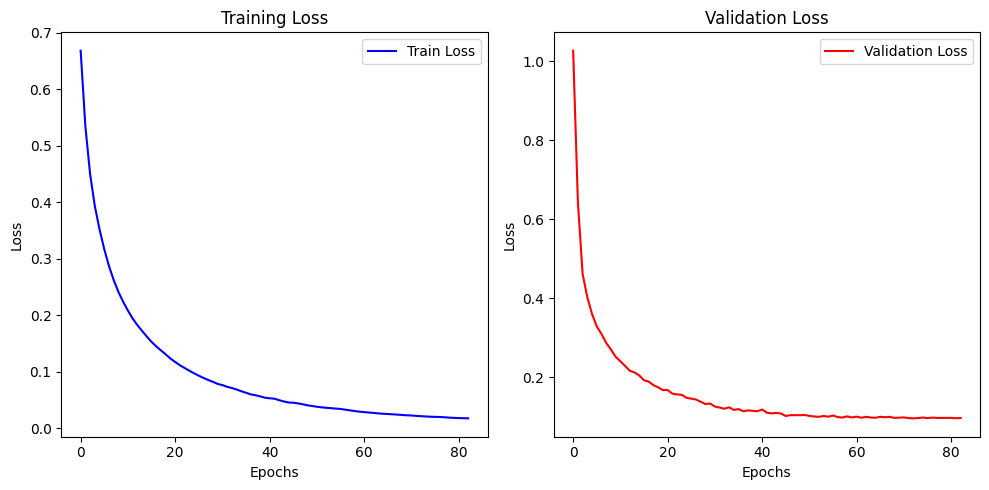

In [ ]:
# Plotting the training and validation losses
plt.figure(figsize=(10, 5))

# Plot train loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss ', color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot validation loss
plt.subplot(1, 2, 2)
plt.plot(val_losses, label='Validation Loss', color='red')
plt.title('Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_path, mask_path, device):
    """Run inference and visualize results."""
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256))
    image = image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (256, 256))

    # Plot Results
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image)

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(mask, cmap="gray")

    plt.subplot(1, 3, 3)
    plt.title("Predicted Mask")
    plt.imshow(output, cmap="gray")

    plt.show()


In [ ]:
# Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

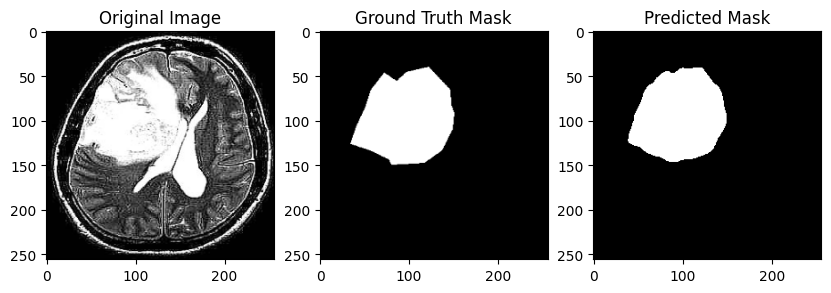

In [ ]:
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)

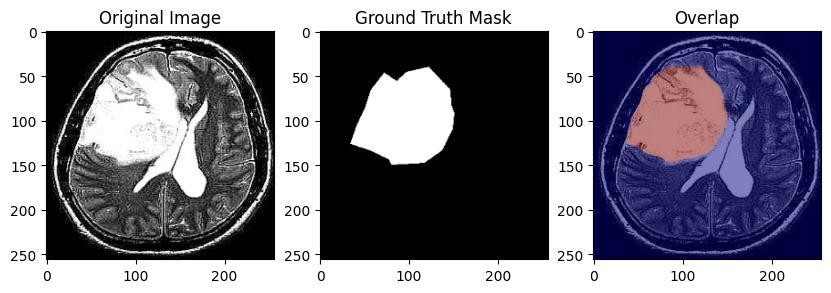

In [ ]:
# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_path, mask_path, device):
    """Run inference and visualize results."""
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256))
    image = image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (256, 256))

    # Plot Results
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image)

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(mask, cmap="gray")

    plt.subplot(1, 3, 3)
    plt.title("Overlap")
    plt.imshow(image)
    plt.imshow(output, cmap='jet', alpha=0.5)  # Overlay predicted mask with transparency

    plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)


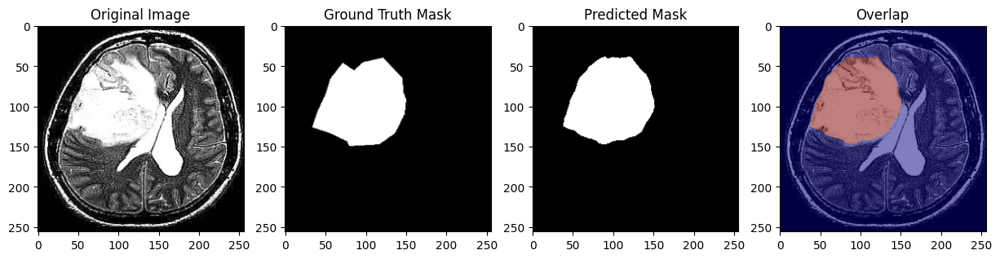

In [ ]:

# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_path, mask_path, device):
    """Run inference and visualize results."""
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256))
    image = image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (256, 256))

    # Plot Results
    plt.figure(figsize=(15, 5))  # Increase figure size for better visibility

    plt.subplot(1, 4, 1)
    plt.title("Original Image")
    plt.imshow(image)

    plt.subplot(1, 4, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(mask, cmap="gray")

    plt.subplot(1, 4, 3)
    plt.title("Predicted Mask")
    plt.imshow(output, cmap="gray")

    plt.subplot(1, 4, 4)
    plt.title("Overlap")
    plt.imshow(image)
    plt.imshow(output, cmap='jet', alpha=0.5)  # Overlay predicted mask with transparency

    plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)


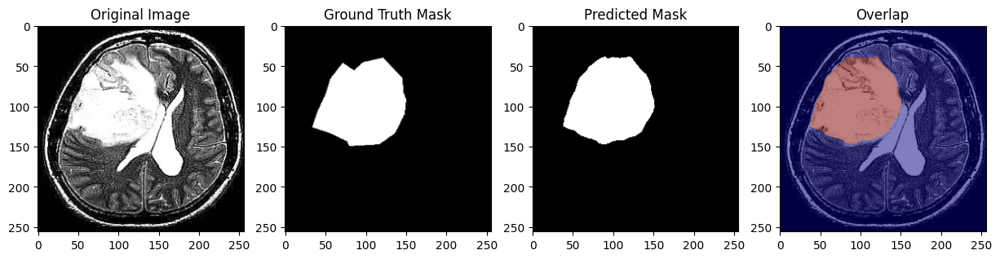

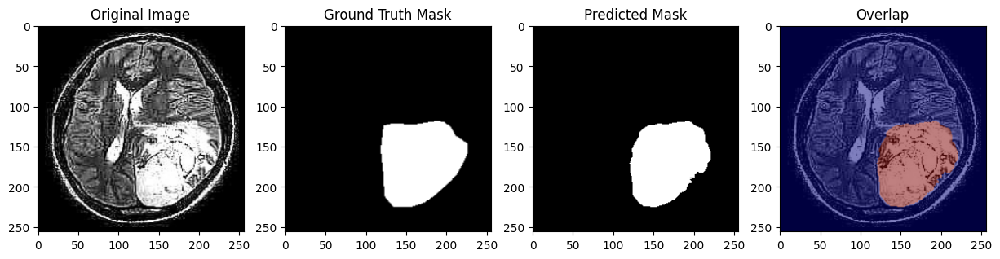

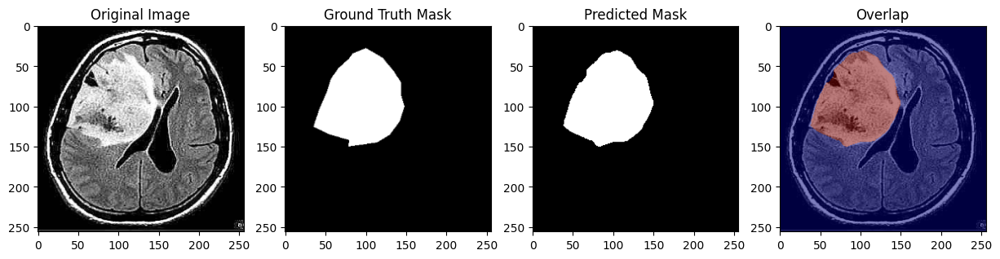

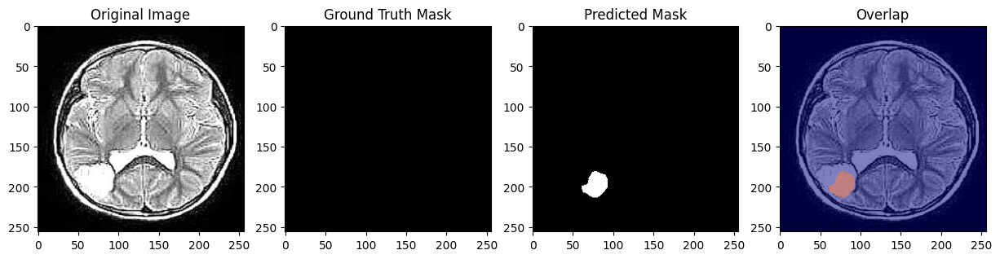

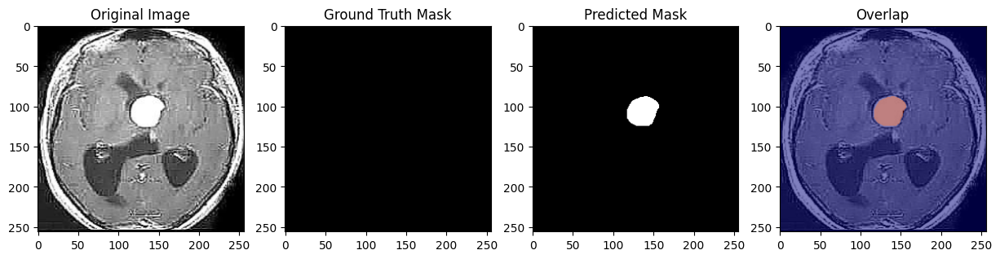

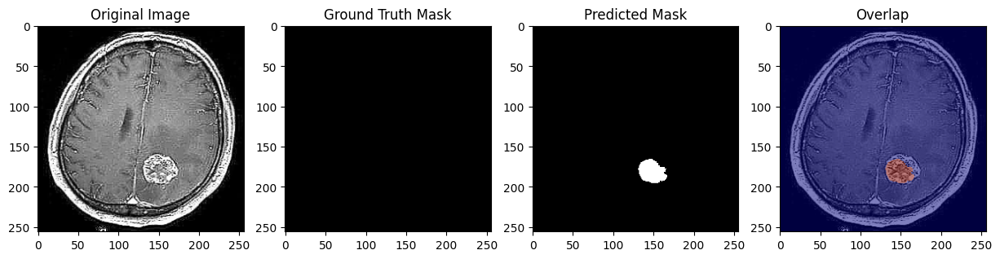

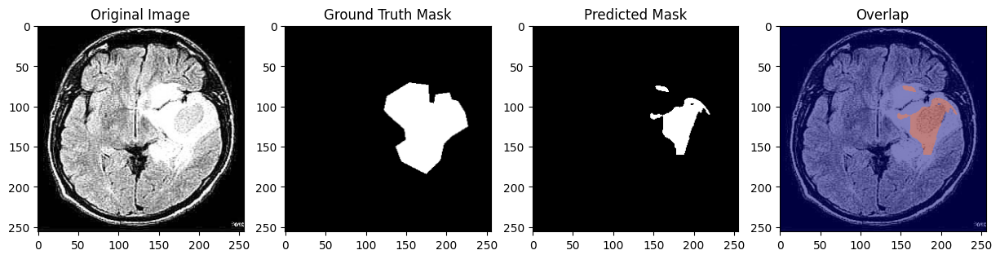

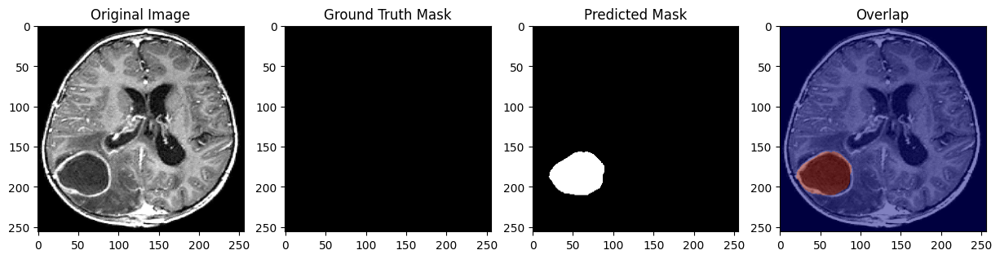

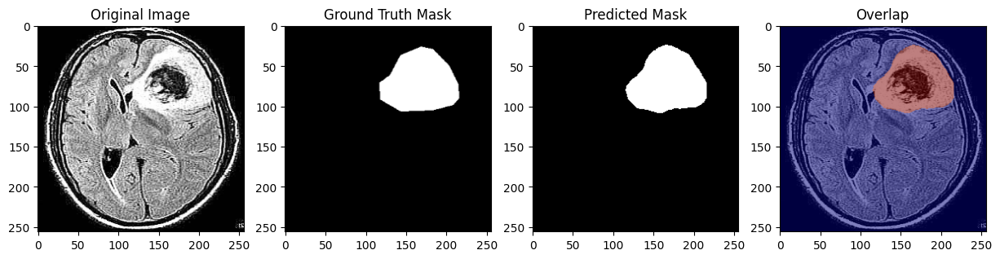

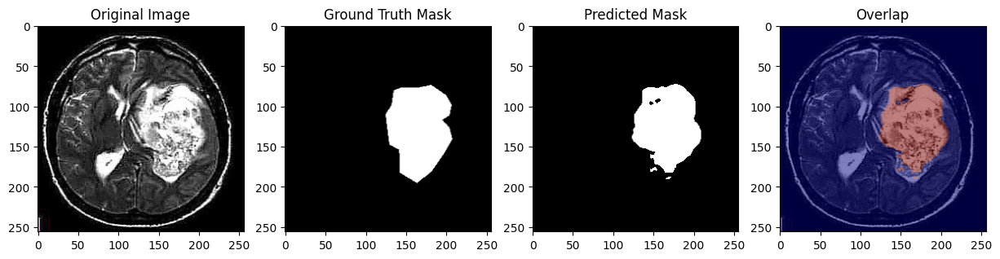

In [ ]:

# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_paths, mask_paths, device, num_images=10):
    """Run inference and visualize results for multiple images."""
    for i in range(min(num_images, len(image_paths))):
        image_path = image_paths[i]
        mask_path = mask_paths[i]

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256, 256))
        image = image.astype("float32") / 255.0

        image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(image_tensor)
            output = torch.sigmoid(output).cpu().squeeze().numpy()
            output = (output > 0.5).astype(np.uint8)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (256, 256))

        # Plot Results
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 4, 1)
        plt.title("Original Image")
        plt.imshow(image)

        plt.subplot(1, 4, 2)
        plt.title("Ground Truth Mask")
        plt.imshow(mask, cmap="gray")

        plt.subplot(1, 4, 3)
        plt.title("Predicted Mask")
        plt.imshow(output, cmap="gray")

        plt.subplot(1, 4, 4)
        plt.title("Overlap")
        plt.imshow(image)
        plt.imshow(output, cmap='jet', alpha=0.5)

        plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

# Test with Multiple Sample Images
infer_and_visualize(model, valid_images, valid_masks, device)


In [ ]:
!pip install gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.2/322.2 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 6.1 MB/s eta 0:00:00


In [ ]:
import gradio as gr
import cv2
import numpy as np
import torch



def predict_mask(image_path):
    """Run inference and return the original image with the predicted mask overlaid with reduced opacity."""

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_image = cv2.resize(image, (256, 256))
    image = original_image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    # Overlay the predicted mask on the original image with reduced opacity
    overlayed_image = original_image.copy()

    # Create the red mask
    red_mask = np.zeros_like(overlayed_image)
    red_mask[output == 1] = [255, 0, 0]  # Mark mask area with red color

    # Apply alpha blending for transparency
    alpha = 0.3  # Control the transparency (lower is more transparent)
    blended_image = cv2.addWeighted(overlayed_image, 1 - alpha, red_mask, alpha, 0)

    # Convert back to BGR for display (Gradio expects BGR)
    blended_image = cv2.cvtColor(blended_image, cv2.COLOR_RGB2BGR)

    return blended_image


# Create the Gradio interface
iface = gr.Interface(
    fn=predict_mask,
    inputs=gr.Image(type="filepath"),
    outputs=gr.Image(type="numpy"),
    title="Brain Tumor Segmentation",
    description="Upload a brain MRI image to predict the tumor mask.",
)

iface.launch()


Running Gradio in a Colab notebook requires sharing enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b84a367eaccc45182b.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Loss & Optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adagrad(model.parameters(), lr=1e-4)


In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5, verbose=True)

# Early stopping setup
early_stopping_patience = 10
best_val_loss = float("inf")
epochs_without_improvement = 0

# Lists to store losses
train_losses2 = []
val_losses2 = []

# Training loop
for epoch in range(100):  # Adjust the number of epochs if needed
    model.train()
    train_loss = 0.0

    # Training phase
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in valid_loader:
            images, masks = images.to(device), masks.to(device)
            output = model(images)
            loss = criterion(output, masks)
            val_loss += loss.item()

    # Average losses
    train_loss /= len(train_loader)
    val_loss /= len(valid_loader)

    print(f"Epoch {epoch}/100, Train Loss: {train_loss}, Val Loss: {val_loss}")

    # Save losses for plotting
    train_losses2.append(train_loss)
    val_losses2.append(val_loss)

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print(f"Saving best model with val_loss {val_loss}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping condition
    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping triggered after {epoch} epochs")
        break

    # Step scheduler
    scheduler.step(val_loss)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 0/100, Train Loss: 0.7324494868516922, Val Loss: 0.8282809853553772
Saving best model with val_loss 0.8282809853553772
Epoch 1/100, Train Loss: 0.6419380940496922, Val Loss: 0.695608879838671
Saving best model with val_loss 0.695608879838671
Epoch 2/100, Train Loss: 0.6085386499762535, Val Loss: 0.6446155650275094
Saving best model with val_loss 0.6446155650275094
Epoch 3/100, Train Loss: 0.5874238573014736, Val Loss: 0.6070399710110256
Saving best model with val_loss 0.6070399710110256
Epoch 4/100, Train Loss: 0.5697085559368134, Val Loss: 0.585640447480338
Saving best model with val_loss 0.585640447480338
Epoch 5/100, Train Loss: 0.5557733699679375, Val Loss: 0.5785809329577855
Saving best model with val_loss 0.5785809329577855
Epoch 6/100, Train Loss: 0.5436092466115952, Val Loss: 0.5637879541942051
Saving best model with val_loss 0.5637879541942051
Epoch 7/100, Train Loss: 0.5303075686097145, Val Loss: 0.5503646901675633
Saving best model with val_loss 0.5503646901675633
Epoc

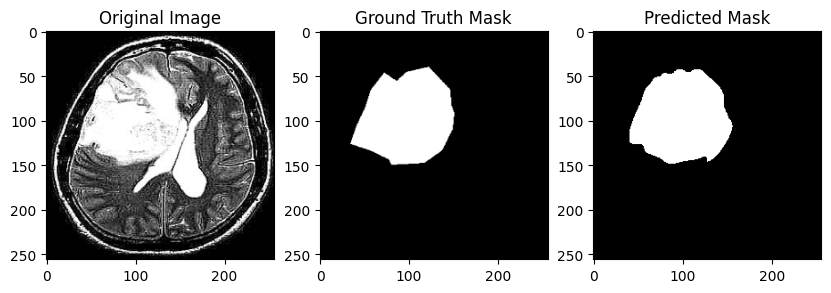

In [ ]:
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)

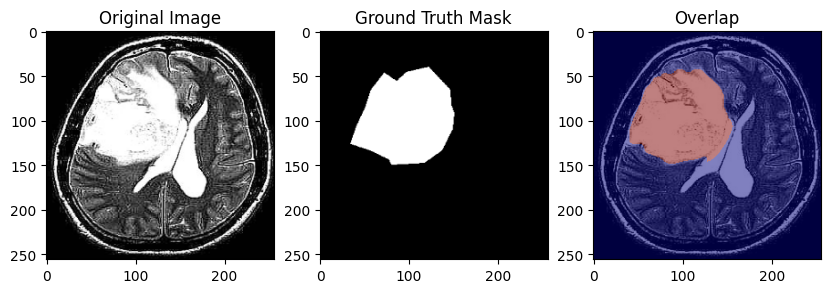

In [ ]:
# prompt: now I want to see the mask in the image as overlap

# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_path, mask_path, device):
    """Run inference and visualize results."""
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256))
    image = image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (256, 256))

    # Plot Results
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image)

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(mask, cmap="gray")

    plt.subplot(1, 3, 3)
    plt.title("Overlap")
    plt.imshow(image)
    plt.imshow(output, cmap='jet', alpha=0.5)  # Overlay predicted mask with transparency

    plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model2.pth"))
model.eval()
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)


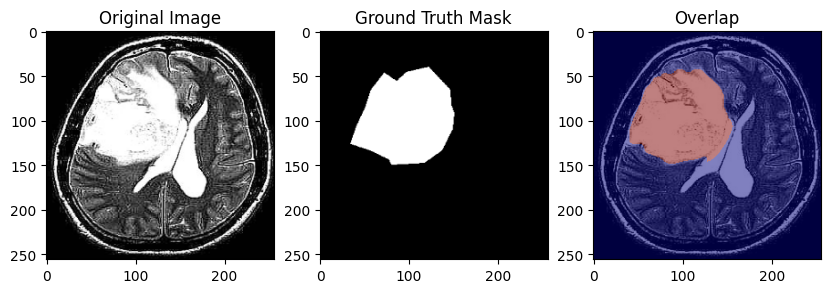

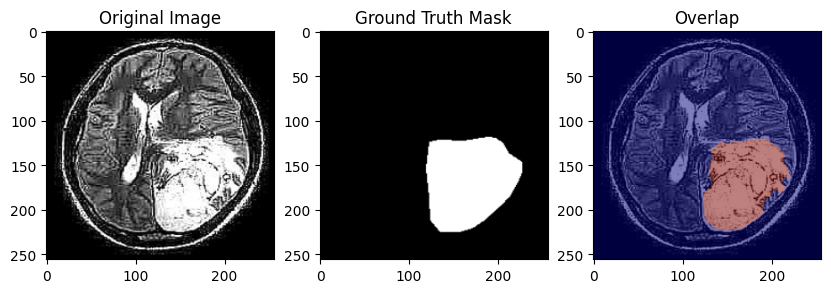

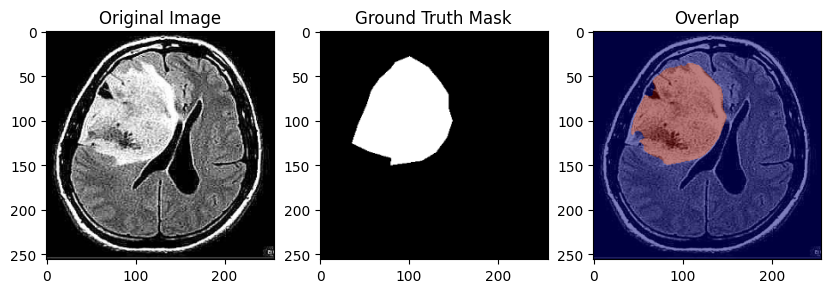

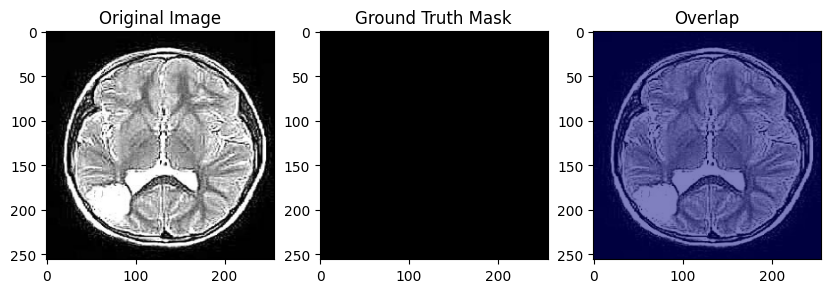

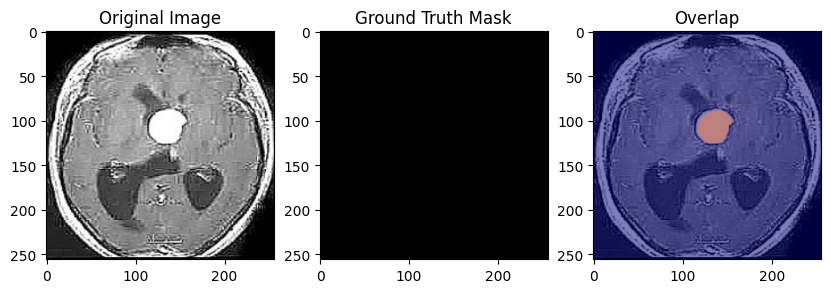

...

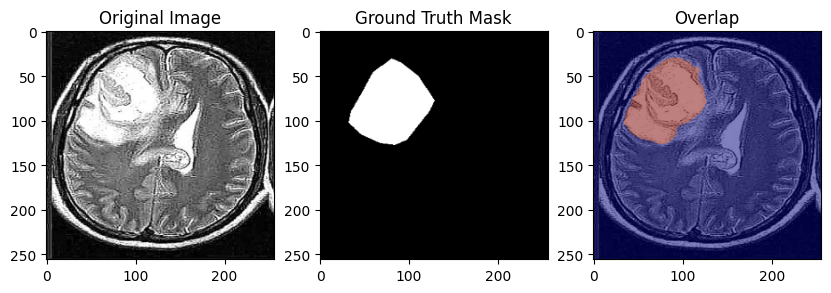

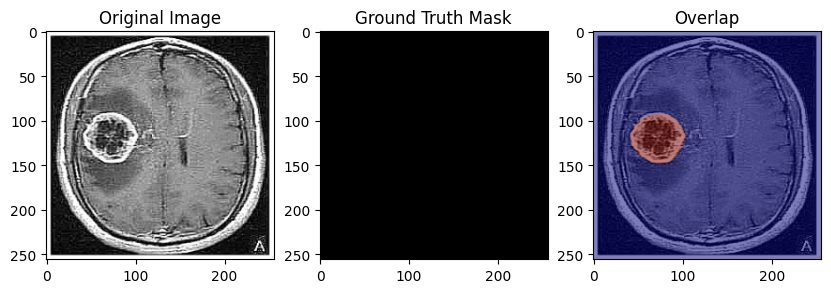

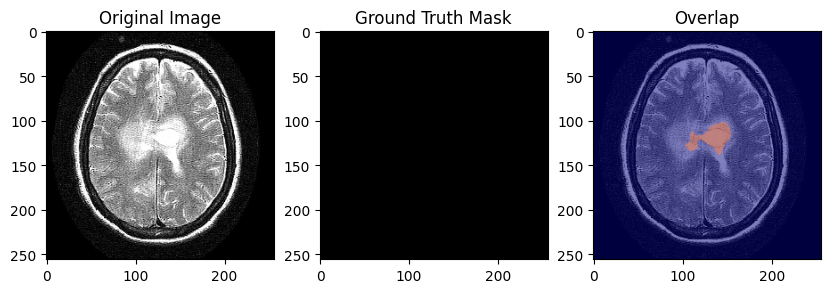

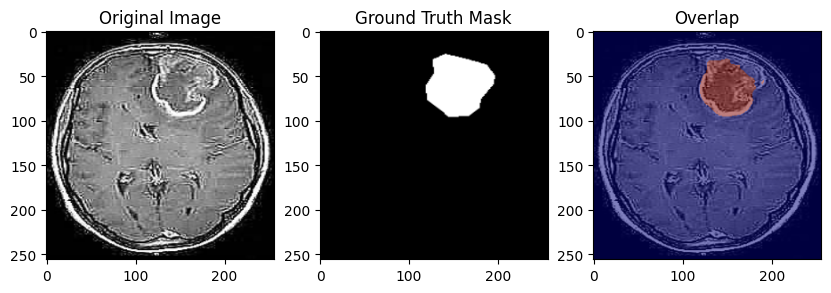

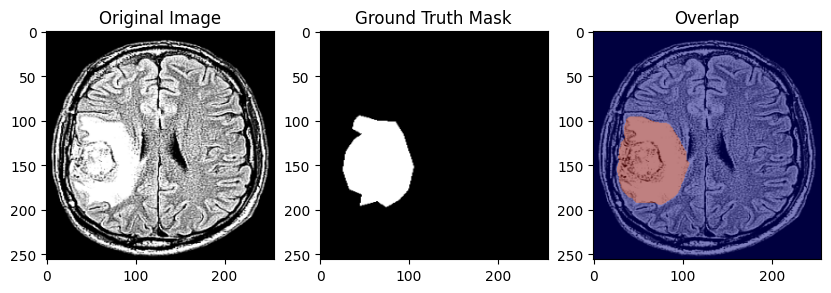

In [ ]:
# prompt: for 10 images

# Assuming you want to visualize the first 10 images from the validation set
for i in range(50):
  if i < len(valid_images) and i < len(valid_masks):
    sample_image = valid_images[i]
    sample_mask = valid_masks[i]
    infer_and_visualize(model, sample_image, sample_mask, device)


In [ ]:
import gradio as gr
import cv2
import numpy as np
import torch



def predict_mask(image_path):
    """Run inference and return the original image with the predicted mask overlaid with reduced opacity."""

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_image = cv2.resize(image, (256, 256))
    image = original_image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    # Overlay the predicted mask on the original image with reduced opacity
    overlayed_image = original_image.copy()

    # Create the red mask
    red_mask = np.zeros_like(overlayed_image)
    red_mask[output == 1] = [255, 0, 0]  # Mark mask area with red color

    # Apply alpha blending for transparency
    alpha = 0.3  # Control the transparency (lower is more transparent)
    blended_image = cv2.addWeighted(overlayed_image, 1 - alpha, red_mask, alpha, 0)

    # Convert back to BGR for display (Gradio expects BGR)
    blended_image = cv2.cvtColor(blended_image, cv2.COLOR_RGB2BGR)

    return blended_image


# Create the Gradio interface
iface = gr.Interface(
    fn=predict_mask,
    inputs=gr.Image(type="filepath"),
    outputs=gr.Image(type="numpy"),
    title="Brain Tumor Segmentation",
    description="Upload a brain MRI image to predict the tumor mask.",
)

iface.launch()


Running Gradio in a Colab notebook requires sharing enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9d38d2fccd7f42790b.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:
# Loss & Optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-4, alpha=0.99, momentum=0.9, weight_decay=1e-5)


In [19]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Learning rate scheduler
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5, verbose=True)

# === 7. Train Model ===
best_loss = float("inf")  # This line is likely redundant, as best_val_loss is used for model saving
epochs = 50
# Lists to store losses
train_loss3 = []
val_loss3 = []

# Initialize best_val_loss before the training loop
best_val_loss = float("inf")
early_stopping_patience = 10
epochs_without_improvement = 0

# Training loop
for epoch in range(100):  # Adjust the number of epochs if needed
    model.train()
    train_loss = 0.0

    # Training phase
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in valid_loader:
            images, masks = images.to(device), masks.to(device)
            output = model(images)
            loss = criterion(output, masks)
            val_loss += loss.item()

    # Average losses
    train_loss /= len(train_loader)
    val_loss /= len(valid_loader)

    print(f"Epoch {epoch}/100, Train Loss: {train_loss}, Val Loss: {val_loss}")

    # Save losses for plotting
    train_loss3.append(train_loss)
    val_loss3.append(val_loss)

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model4.pth")
        print(f"Saving best model with val_loss {val_loss}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping condition
    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping triggered after {epoch} epochs")
        break

    # Step scheduler
    scheduler.step(val_loss)


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 0/100, Train Loss: 0.10993005335330963, Val Loss: 0.17349299362727574
Saving best model with val_loss 0.17349299362727574
Epoch 1/100, Train Loss: 0.09010905167087913, Val Loss: 0.12488224250929696
Saving best model with val_loss 0.12488224250929696
Epoch 2/100, Train Loss: 0.07682745181955397, Val Loss: 0.1078558691910335
Saving best model with val_loss 0.1078558691910335
Epoch 3/100, Train Loss: 0.05849844962358475, Val Loss: 0.06695767758148057
Saving best model with val_loss 0.06695767758148057
Epoch 4/100, Train Loss: 0.05345690669491887, Val Loss: 0.09053985668080193
Epoch 5/100, Train Loss: 0.04948063171468675, Val Loss: 0.06795787438750267
Epoch 6/100, Train Loss: 0.04135942226275802, Val Loss: 0.06609782150813512
Saving best model with val_loss 0.06609782150813512
Epoch 7/100, Train Loss: 0.037932692328467965, Val Loss: 0.061539550977093835
Saving best model with val_loss 0.061539550977093835
Epoch 8/100, Train Loss: 0.03713376820087433, Val Loss: 0.08719516332660403
Epo

In [20]:
# Create a dictionary to store the losses
loss_data = {
    "train_losses": train_loss3,
    "val_losses": val_loss3
}

# Save the dictionary to a JSON file
with open("training_losses_RMSprop.json", "w") as f:
  json.dump(loss_data, f)


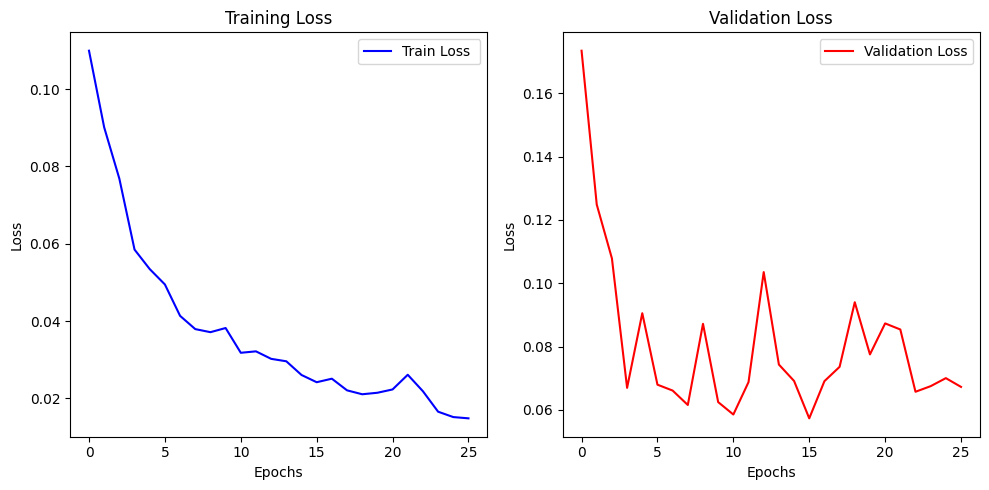

In [21]:
# Plotting the training and validation losses
plt.figure(figsize=(10, 5))

# Plot train loss
plt.subplot(1, 2, 1)
plt.plot(train_loss3, label='Train Loss ', color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot validation loss
plt.subplot(1, 2, 2)
plt.plot(val_loss3, label='Validation Loss', color='red')
plt.title('Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

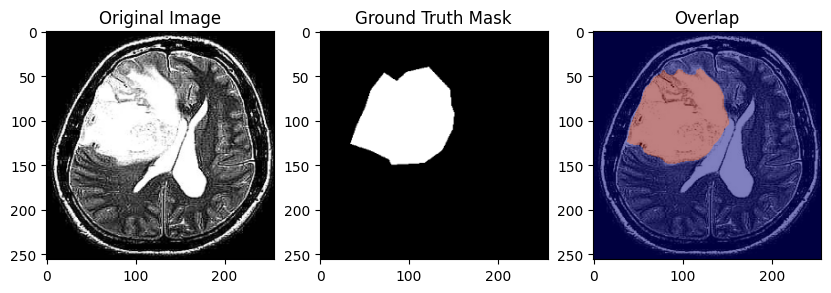

In [53]:
# prompt: now I want to see the mask in the image as overlap

# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_path, mask_path, device):
    """Run inference and visualize results."""
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256))
    image = image.astype("float32") / 255.0

    image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (256, 256))

    # Plot Results
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image)

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(mask, cmap="gray")

    plt.subplot(1, 3, 3)
    plt.title("Overlap")
    plt.imshow(image)
    plt.imshow(output, cmap='jet', alpha=0.5)  # Overlay predicted mask with transparency

    plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model4.pth"))
model.eval()
# Test with a Sample Image
sample_image = valid_images[0]
sample_mask = valid_masks[0]
infer_and_visualize(model, sample_image, sample_mask, device)


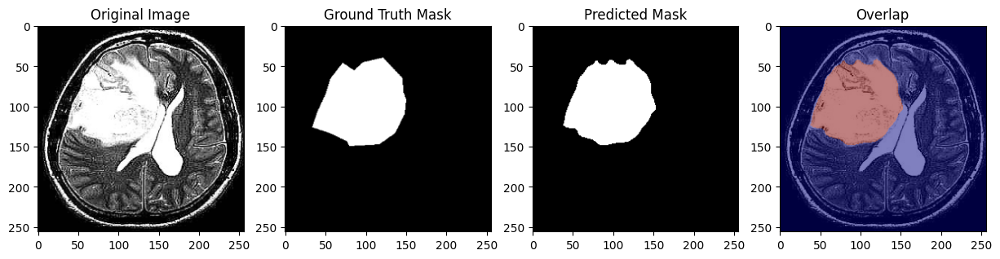

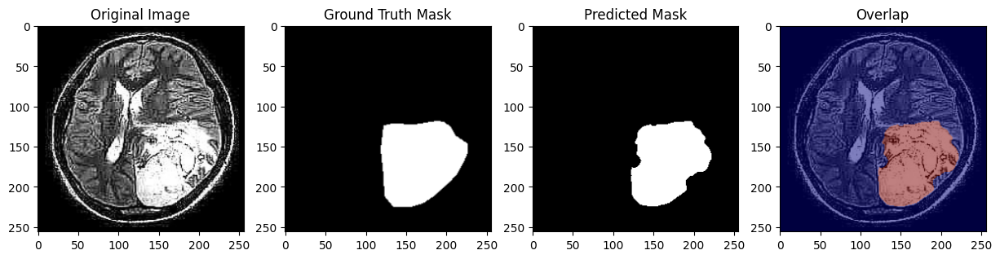

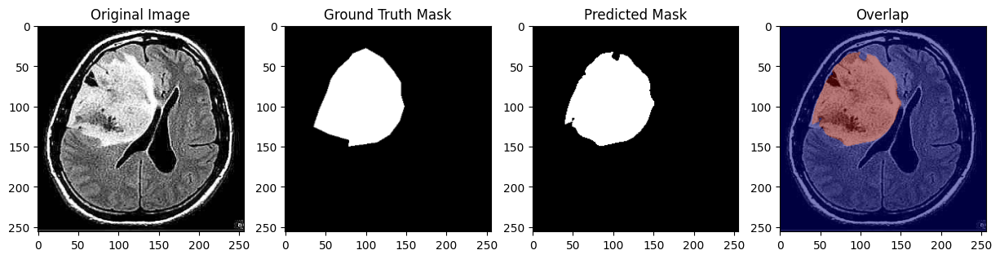

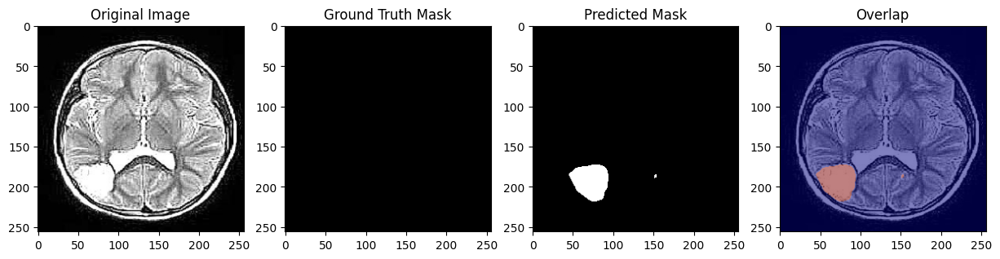

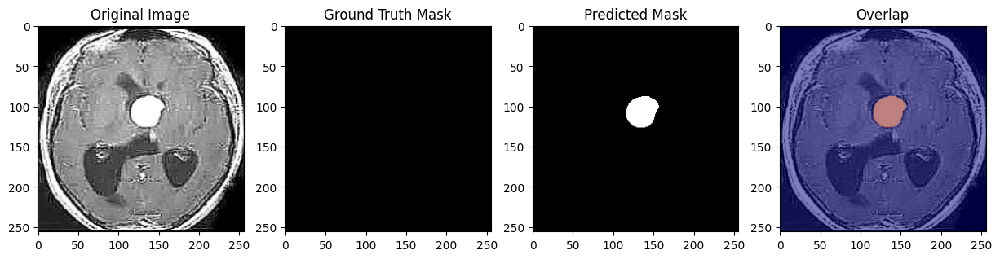

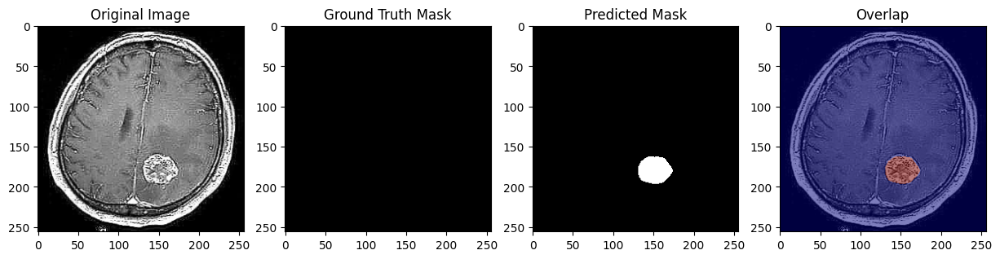

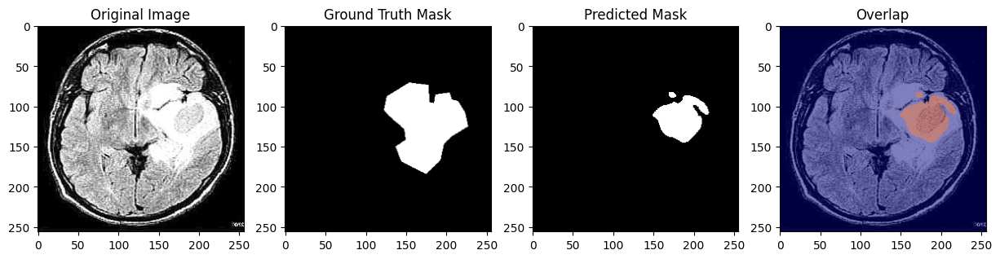

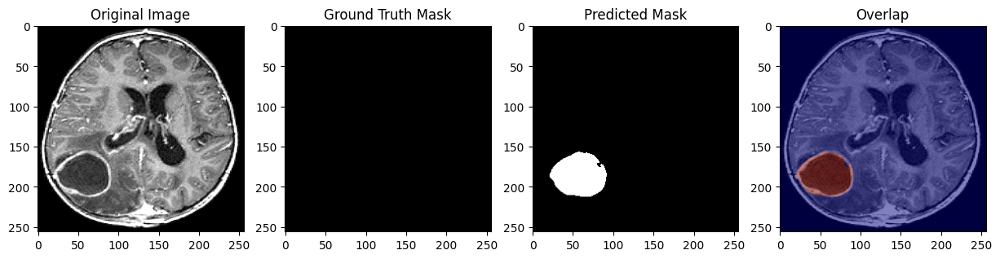

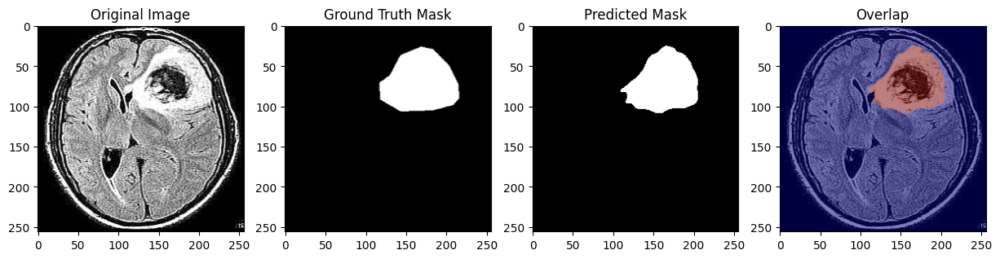

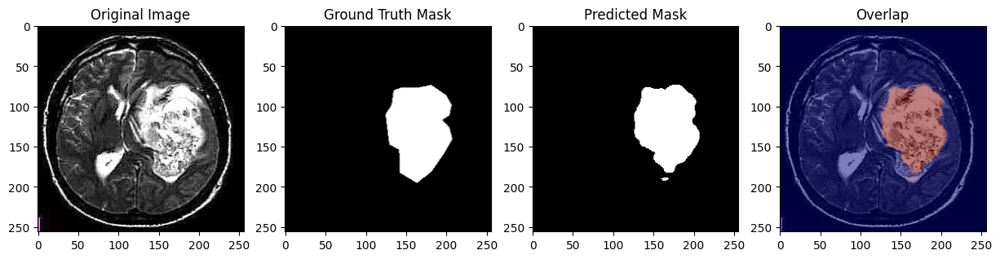

In [58]:

# === 8. Inference & Visualization ===
def infer_and_visualize(model, image_paths, mask_paths, device, num_images=10):
    """Run inference and visualize results for multiple images."""
    for i in range(min(num_images, len(image_paths))):
        image_path = image_paths[i]
        mask_path = mask_paths[i]

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256, 256))
        image = image.astype("float32") / 255.0

        image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(image_tensor)
            output = torch.sigmoid(output).cpu().squeeze().numpy()
            output = (output > 0.5).astype(np.uint8)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (256, 256))

        # Plot Results
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 4, 1)
        plt.title("Original Image")
        plt.imshow(image)

        plt.subplot(1, 4, 2)
        plt.title("Ground Truth Mask")
        plt.imshow(mask, cmap="gray")

        plt.subplot(1, 4, 3)
        plt.title("Predicted Mask")
        plt.imshow(output, cmap="gray")

        plt.subplot(1, 4, 4)
        plt.title("Overlap")
        plt.imshow(image)
        plt.imshow(output, cmap='jet', alpha=0.5)

        plt.show()

# Load Best Model
model.load_state_dict(torch.load("best_model4.pth"))
model.eval()

# Test with Multiple Sample Images
infer_and_visualize(model, valid_images, valid_masks, device)


In [54]:
!pip install gradio

In [57]:
import gradio as gr
import cv2
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def predict_mask(image_path):
    """Run inference and return the original image with the predicted mask overlaid with reduced opacity."""

    # Load and preprocess the image
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_size = (image.shape[1], image.shape[0])  # Save original size (width, height)

    # Resize image to model input size (256x256)
    resized_image = cv2.resize(image, (256, 256)).astype("float32") / 255.0

    # Convert to tensor and run inference
    image_tensor = torch.tensor(resized_image).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        output = torch.sigmoid(output).cpu().squeeze().numpy()
        output = (output > 0.5).astype(np.uint8)

    # Resize the output mask back to the original image size
    output_resized = cv2.resize(output, original_size, interpolation=cv2.INTER_NEAREST)

    # Overlay the predicted mask on the original image with reduced opacity
    overlayed_image = image.copy()

    # Create the red mask
    red_mask = np.zeros_like(overlayed_image)
    red_mask[output_resized == 1] = [255, 0, 0]  # Mark mask area with red color

    # Apply alpha blending for transparency
    alpha = 0.3  # Control the transparency (lower is more transparent)
    blended_image = cv2.addWeighted(overlayed_image, 1 - alpha, red_mask, alpha, 0)

    # Convert back to BGR for display (Gradio expects BGR)
    blended_image = cv2.cvtColor(blended_image, cv2.COLOR_RGB2BGR)

    return blended_image


# Create the Gradio interface
iface = gr.Interface(
    fn=predict_mask,
    inputs=gr.Image(type="filepath"),
    outputs=gr.Image(type="numpy"),
    title="Brain Tumor Semantic Segmentation",
    description="Upload a brain MRI image to predict the tumor mask.",
)

iface.launch()


Running Gradio in a Colab notebook requires sharing enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6fdb12cfedaf5bdfe9.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
